# Task 1: Retail Sales Data Cleaning
**Author: Ishita Misra | WeIntern Week 2**
Synthetic practice dataset. Run from this repository after installing requirements. This notebook retains the supplied IQR strategy, trims product and identifier whitespace, and checks duplicates after normalization. Statistical outliers in sales are retained; capping price/quantity independently can break transaction arithmetic, so recorded sales/profit are analyzed as supplied rather than recomputed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

In [2]:
# Load the raw dataset. Update this path if your file is stored elsewhere.
# Resolve project root in a repository checkout or a Colab Drive folder.
from pathlib import Path
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent,
    Path('/content/drive/MyDrive/retail-sales-week2')]
    if (p / 'data/raw/retail_sales_raw.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open from the extracted retail-sales-week2 folder; see README for Colab setup.')
DATA_PATH = PROJECT_ROOT / 'data/raw/retail_sales_raw.csv'
OUTPUT_DIR = PROJECT_ROOT / 'reports/cleaning'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Raw dataset not found: {DATA_PATH}. Update DATA_PATH to the correct CSV location.')

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()

print('Shape:', raw_df.shape)
display(raw_df.head())
raw_df.info()
display(raw_df.describe(include='all').T)
print('Exact duplicate rows:', raw_df.duplicated().sum())

Shape: (12185, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12185 entries, 0 to 12184
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          12185 non-null  object 
 1   Order Date        12185 non-null  object 
 2   Ship Date         12185 non-null  object 
 3   Store ID          12185 non-null  object 
 4   Region            12039 non-null  object 
 5   Customer Segment  12003 non-null  object 
 6   Product ID        12185 non-null  object 
 7   Product Name      12185 non-null  object 
 8   Product Category  12064 non-null  object 
 9   Quantity          12089 non-null  float64
 10  Unit Price        12064 non-null  float64
 11  Discount          12040 non-null  float64
 12  Promotion         12185 non-null  object 
 13  Sales             12113 non-null  float64
 14  Cost Price        12185 non-null  float64
 15  Shipping Cost     12039 non-null  float64
 16  Profit            121

    Order ID  Order Date   Ship Date Store ID     Region Customer Segment Product ID   Product Name        Product Category  Quantity  Unit Price  Discount      Promotion     Sales  Cost Price  Shipping Cost   Profit Payment Method Sales Channel  Holiday Flag Order Status
0  ORD000001  2023-04-08  2023-04-10    ST101      North         Consumer      P3001  Running Shoes                 Fashion       7.0     3022.96     0.082  Festival Sale  19890.12     1610.25           5.96  8612.41            UPI      In-Store             0     Returned
1  ORD000002  2025-04-28  2025-05-01    ST303       East         Consumer      P5001   Skincare Kit  Beauty & Personal Care       3.0     1351.45     0.107   No Promotion   4574.92      657.02         100.97  2502.89           Cash        Online             0    Completed
2  ORD000003  2024-12-18  2024-12-18    ST401       West         Consumer      P2003   Bedsheet Set          Home & Kitchen       5.0     1614.89     0.072   No Promotion   9323.44 

                    count unique           top   freq          mean           std       min       25%      50%       75%        max
Order ID            12185  12000     ORD008624      2           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Order Date          12185   1110    2025-03-28     25           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Ship Date           12185   1100    2025-05-27     23           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Store ID            12185     15         ST302    856           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Region              12039     10         South   2265           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Customer Segment    12003      3      Consumer   8567           NaN           NaN       NaN       NaN      NaN       NaN        NaN
Product ID          12185     20         P3002    699           NaN         

                  missing_count  missing_percent
Payment Method              219             1.80
Customer Segment            182             1.49
Shipping Cost               146             1.20
Region                      146             1.20
Discount                    145             1.19
Unit Price                  121             0.99
Product Category            121             0.99
Sales Channel               120             0.98
Quantity                     96             0.79
Sales                        72             0.59

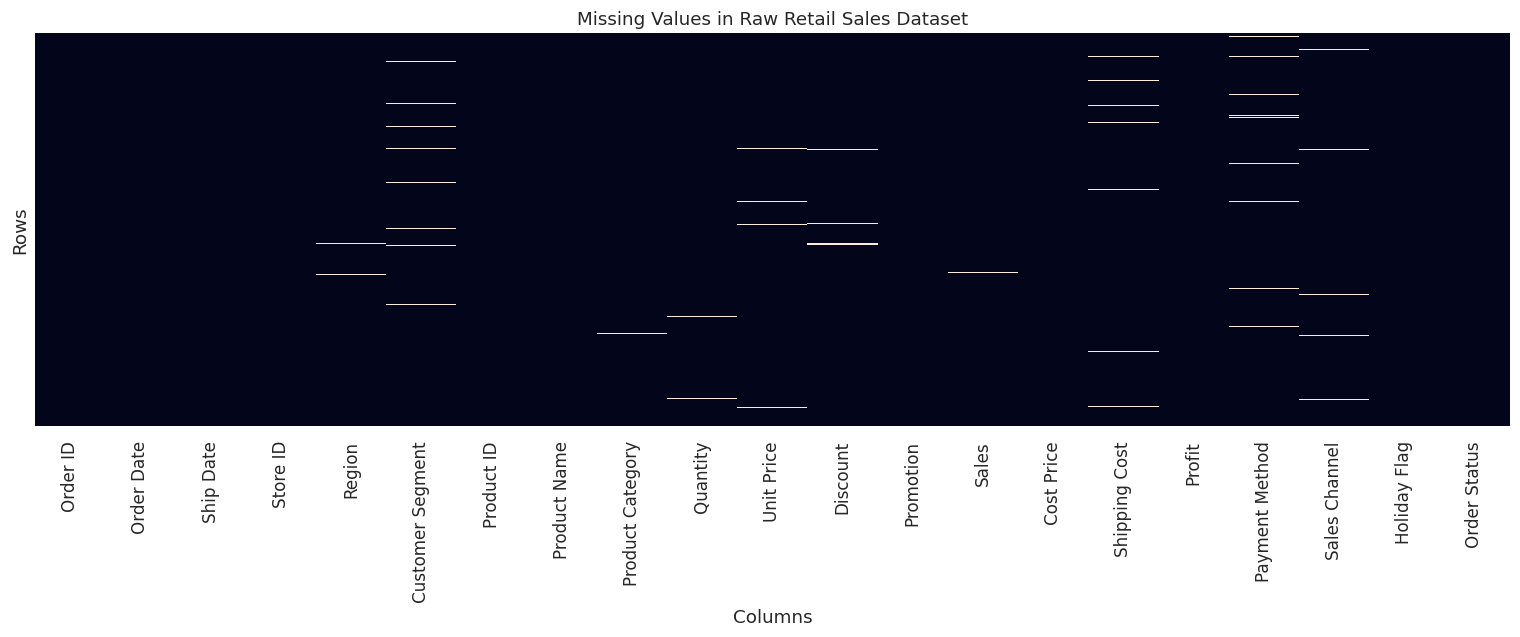

In [3]:
# Missing-value counts and heatmap (before cleaning)
missing_summary = pd.DataFrame({
    'missing_count': raw_df.isna().sum(),
    'missing_percent': (raw_df.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
display(missing_summary[missing_summary['missing_count'] > 0])

plt.figure(figsize=(14, 6))
sns.heatmap(raw_df.isna(), cbar=False, yticklabels=False)
plt.title('Missing Values in Raw Retail Sales Dataset')
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()

In [4]:
# Remove exact duplicate rows first. Keep raw_df unchanged for comparison.
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
duplicates_removed = duplicates_before - int(df.duplicated().sum())
print(f'Exact duplicate rows found: {duplicates_before:,}')
print(f'Exact duplicate rows removed: {duplicates_removed:,}')

Exact duplicate rows found: 120
Exact duplicate rows removed: 120


## Missing-value strategy

Categorical fields are filled with `unknown`; missing numeric transaction attributes are median-imputed. Missing `sales` values are not invented because `sales` is a target/important business measure, so those rows are excluded from the analysis-ready output. Invalid dates and impossible transaction values are counted and excluded. Each decision is also written into the generated cleaning report.

In [5]:
#duplicate value treatment
df.duplicated().sum()
df[df.duplicated(keep=False)].head(6)
df = df.drop_duplicates()
print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


## 5. Standardize column names

Convert names to lowercase `snake_case` to make columns consistent and easier to reference.

In [6]:
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r'\s+', '_', regex=True)
      .str.replace(r'[^a-z0-9_]', '', regex=True)
)
print(df.columns.tolist())

['order_id', 'order_date', 'ship_date', 'store_id', 'region', 'customer_segment', 'product_id', 'product_name', 'product_category', 'quantity', 'unit_price', 'discount', 'promotion', 'sales', 'cost_price', 'shipping_cost', 'profit', 'payment_method', 'sales_channel', 'holiday_flag', 'order_status']


In [7]:
# Correct date types. Mixed date formats are parsed consistently; invalid values become NaT.
date_cols = ['order_date', 'ship_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format='mixed', errors='coerce', dayfirst=True)

print('Date parsing results:')
for col in date_cols:
    print(f'{col}: {df[col].isna().sum()} missing/unparseable values')
print(df[date_cols].dtypes)

Date parsing results:
order_date: 5 missing/unparseable values
ship_date: 0 missing/unparseable values
order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object


In [8]:
# Convert numeric columns; invalid strings become NaN and are handled below.
numeric_cols = ['quantity', 'unit_price', 'discount', 'sales', 'cost_price', 'shipping_cost', 'profit']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(df[numeric_cols].dtypes)

quantity         float64
unit_price       float64
discount         float64
sales            float64
cost_price       float64
shipping_cost    float64
profit           float64
dtype: object


In [9]:
# Trim all text fields, including product_name and identifiers. Preserve display-name case.
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('string').str.strip()
# Standardize categorical text and normalize missing-like strings.
categorical_cols = [
    'region', 'customer_segment', 'product_category', 'promotion',
    'payment_method', 'sales_channel', 'order_status'
]
for col in categorical_cols:
    df[col] = df[col].astype('string').str.strip().str.lower()
    df[col] = df[col].mask(df[col].isin({'', 'nan', 'none', 'null'}), pd.NA)

for col in categorical_cols:
    print(f'\n{col}:')
    display(df[col].value_counts(dropna=False).head(15).to_frame('count'))


region:

customer_segment:

product_category:

promotion:

payment_method:

sales_channel:

order_status:


         count
region        
south     2429
central   2397
east      2376
west      2370
north     2348
<NA>       145

                  count
customer_segment       
consumer           8478
corporate          2052
small business     1355
<NA>                180

                        count
product_category             
fashion                  2665
home & kitchen           2529
grocery                  2473
electronics              2396
beauty & personal care   1882
<NA>                      120

               count
promotion           
no promotion    6342
festival sale   2493
member offer    2020
clearance       1210

                count
payment_method       
upi              4505
credit card      2605
debit card       2082
cash             1428
net banking      1228
<NA>              217

               count
sales_channel       
in-store        7450
online          4495
<NA>             120

              count
order_status       
completed     11359
returned        485
cancelled       221

In [10]:
# Missing-value treatment decisions:
# - categorical descriptors -> 'unknown'
# - numeric transaction attributes -> median imputation
# - missing Sales (target) -> do not invent values; exclude those rows from analysis-ready data
# - invalid/unparseable dates -> exclude rows because transaction timing is important
# - impossible discounts (<0 or >1) -> replace with median of valid discounts

for col in categorical_cols:
    df[col] = df[col].fillna('unknown')

for col in ['quantity', 'unit_price', 'discount', 'shipping_cost', 'cost_price', 'profit']:
    if df[col].isna().any():
        median_value = df[col].median()
        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

invalid_discount_mask = (df['discount'] < 0) | (df['discount'] > 1)
invalid_discount_count = int(invalid_discount_mask.sum())
df.loc[invalid_discount_mask, 'discount'] = np.nan
valid_discount_median = df.loc[df['discount'].between(0, 1), 'discount'].median()
if pd.notna(valid_discount_median):
    df['discount'] = df['discount'].fillna(valid_discount_median)

missing_sales_rows = int(df['sales'].isna().sum())
df = df.dropna(subset=['sales']).copy()
invalid_date_mask = df[date_cols].isna().any(axis=1)
invalid_date_rows = int(invalid_date_mask.sum())
df = df.loc[~invalid_date_mask].copy()

invalid_transaction_mask = (
    (df['quantity'] <= 0) | (df['unit_price'] < 0) |
    (df['cost_price'] < 0) | (df['shipping_cost'] < 0)
)
invalid_transaction_rows = int(invalid_transaction_mask.sum())
df = df.loc[~invalid_transaction_mask].copy()

print(f'Missing sales rows excluded: {missing_sales_rows:,}')
print(f'Rows with missing/unparseable dates excluded: {invalid_date_rows:,}')
print(f'Invalid transaction rows excluded: {invalid_transaction_rows:,}')
print(f'Invalid discounts corrected: {invalid_discount_count:,}')
print('Missing cells remaining:', int(df.isna().sum().sum()))
display(df.isna().sum().to_frame('missing_count'))

Missing sales rows excluded: 72
Rows with missing/unparseable dates excluded: 5
Invalid transaction rows excluded: 0
Invalid discounts corrected: 1
Missing cells remaining: 0


                  missing_count
order_id                      0
order_date                    0
ship_date                     0
store_id                      0
region                        0
customer_segment              0
product_id                    0
product_name                  0
product_category              0
quantity                      0
unit_price                    0
discount                      0
promotion                     0
sales                         0
cost_price                    0
shipping_cost                 0
profit                        0
payment_method                0
sales_channel                 0
holiday_flag                  0
order_status                  0

Values capped: {'quantity': 96, 'unit_price': 1151, 'shipping_cost': 0}
Sales and profit outliers were retained and documented.
Additional exact duplicates removed after capping: 65


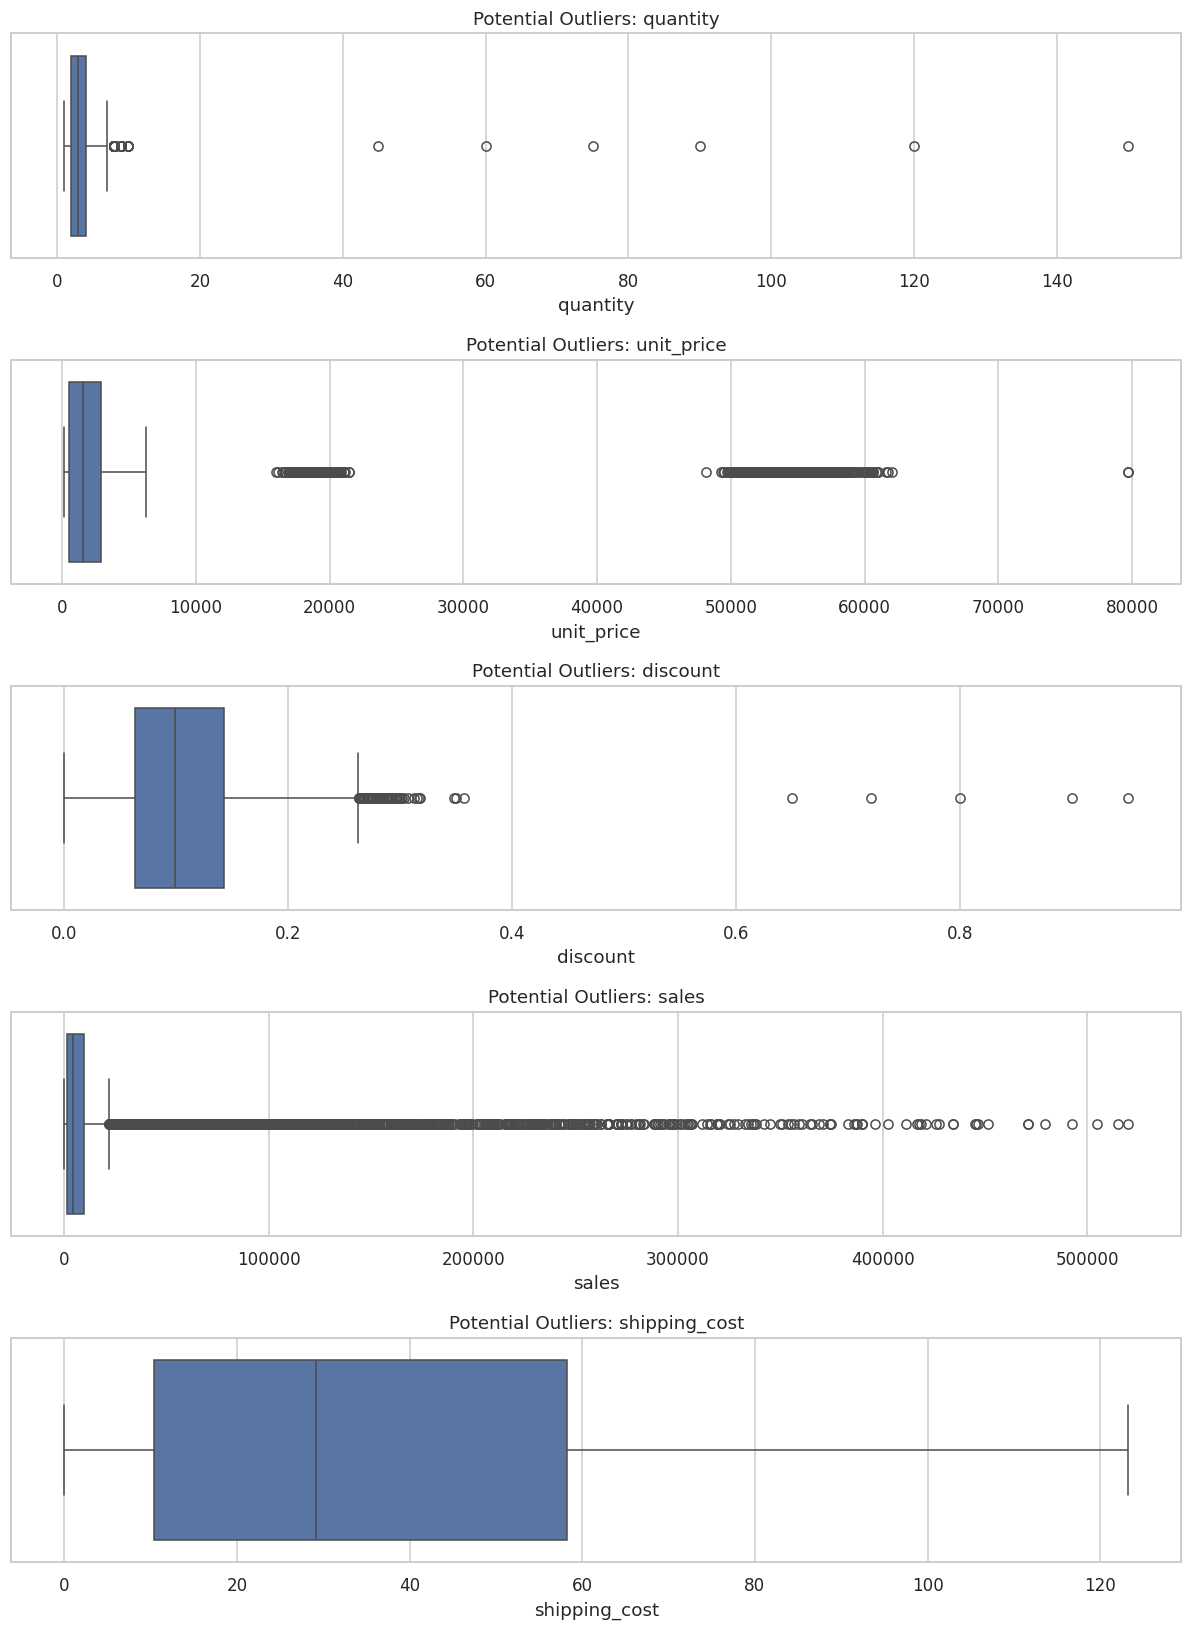

          column         q1         q3        iqr  lower_fence  upper_fence  outliers_before_treatment            treatment
0       quantity     2.0000     4.0000     2.0000     -1.00000      7.00000                         96          IQR capping
1     unit_price   507.9675  2921.6300  2413.6625  -3112.52625   6542.12375                       1151          IQR capping
2       discount     0.0630     0.1430     0.0800     -0.05700      0.26300                         93  retained for review
3          sales  1652.1700  9808.3875  8156.2175 -10582.15625  22042.71375                       1218  retained for review
4  shipping_cost    10.3500    58.2025    47.8525    -61.42875    129.98125                          0          IQR capping

In [11]:
# Detect potential outliers with boxplots and IQR fences.
# IQR flags are not automatically errors. Cap quantity, unit_price, shipping_cost;
# retain sales/profit outliers because they may represent genuine large transactions.
outlier_cols = ['quantity', 'unit_price', 'discount', 'sales', 'shipping_cost']
fig, axes = plt.subplots(len(outlier_cols), 1, figsize=(11, 3 * len(outlier_cols)))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Potential Outliers: {col}')
plt.tight_layout()
plt.show()

outlier_records = []
for col in outlier_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    treatment = 'IQR capping' if col in ['quantity', 'unit_price', 'shipping_cost'] else 'retained for review'
    outlier_records.append({
        'column': col, 'q1': q1, 'q3': q3, 'iqr': iqr,
        'lower_fence': lower, 'upper_fence': upper,
        'outliers_before_treatment': int(mask.sum()), 'treatment': treatment
    })
outlier_report = pd.DataFrame(outlier_records)
display(outlier_report)

capped_counts = {}
for col in ['quantity', 'unit_price', 'shipping_cost']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = max(0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    capped_counts[col] = int(mask.sum())
    df[col] = df[col].clip(lower=lower, upper=upper)

print('Values capped:', capped_counts)
print('Sales and profit outliers were retained and documented.')

# Capping can occasionally make two rows identical; re-check and remove exact duplicates.
duplicates_after_capping = int(df.duplicated().sum())
if duplicates_after_capping:
    df = df.drop_duplicates().copy()
print(f'Additional exact duplicates removed after capping: {duplicates_after_capping:,}')

In [12]:
# Validate the final cleaned dataset.
print('Cleaned shape:', df.shape)
print('Exact duplicate rows remaining:', int(df.duplicated().sum()))
print('Total missing cells remaining:', int(df.isna().sum().sum()))
df.info()
display(df.describe(include='all').T)

print('Discounts outside [0, 1]:', int((~df['discount'].between(0, 1)).sum()))
print('Non-positive quantities:', int((df['quantity'] <= 0).sum()))
print('Negative unit prices:', int((df['unit_price'] < 0).sum()))
print('Negative shipping costs:', int((df['shipping_cost'] < 0).sum()))
print('Ship date before order date:', int((df['ship_date'] < df['order_date']).sum()))

print('Remaining missing values by column:')
display(df.isna().sum().to_frame('missing_count'))
assert not df['order_id'].duplicated().any(), 'Review conflicting repeated order IDs before submitting.'
assert df['product_name'].eq(df['product_name'].str.strip()).all()


Cleaned shape: (11923, 21)
Exact duplicate rows remaining: 0
Total missing cells remaining: 0
<class 'pandas.core.frame.DataFrame'>
Index: 11923 entries, 0 to 11999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          11923 non-null  string        
 1   order_date        11923 non-null  datetime64[ns]
 2   ship_date         11923 non-null  datetime64[ns]
 3   store_id          11923 non-null  string        
 4   region            11923 non-null  string        
 5   customer_segment  11923 non-null  string        
 6   product_id        11923 non-null  string        
 7   product_name      11923 non-null  string        
 8   product_category  11923 non-null  string        
 9   quantity          11923 non-null  float64       
 10  unit_price        11923 non-null  float64       
 11  discount          11923 non-null  float64       
 12  promotion         11923 non-null  string 

                    count unique           top   freq                           mean                  min                  25%                  50%                  75%                  max           std
order_id            11923  11923     ORD000001      1                            NaN                  NaN                  NaN                  NaN                  NaN                  NaN           NaN
order_date          11923    NaN           NaN    NaN  2024-06-28 12:10:34.068606976  2023-01-01 00:00:00  2023-09-30 00:00:00  2024-06-28 00:00:00  2025-03-28 00:00:00  2025-12-31 00:00:00           NaN
ship_date           11923    NaN           NaN    NaN  2024-06-29 08:54:11.262266368  2023-01-01 00:00:00  2023-10-01 00:00:00  2024-06-29 00:00:00  2025-03-29 00:00:00  2026-01-04 00:00:00           NaN
store_id            11923     15         ST302    836                            NaN                  NaN                  NaN                  NaN                  NaN                

                  missing_count
order_id                      0
order_date                    0
ship_date                     0
store_id                      0
region                        0
customer_segment              0
product_id                    0
product_name                  0
product_category              0
quantity                      0
unit_price                    0
discount                      0
promotion                     0
sales                         0
cost_price                    0
shipping_cost                 0
profit                        0
payment_method                0
sales_channel                 0
holiday_flag                  0
order_status                  0

In [13]:
# Encode categories in a separate copy; keep the main cleaned CSV human-readable.
encoding_cols = ['region', 'customer_segment', 'product_category', 'promotion',
                 'payment_method', 'sales_channel', 'order_status']
df_encoded = pd.get_dummies(df, columns=encoding_cols, dtype=int)
print('Cleaned dataset shape:', df.shape)
print('Encoded dataset shape:', df_encoded.shape)
display(df_encoded.head())

# Before/after quality metrics

def quality_metrics(frame, stage):
    return {
        'stage': stage,
        'rows': int(frame.shape[0]),
        'columns': int(frame.shape[1]),
        'missing_cells': int(frame.isna().sum().sum()),
        'columns_with_missing_values': int((frame.isna().sum() > 0).sum()),
        'exact_duplicate_rows': int(frame.duplicated().sum())
    }

comparison = pd.DataFrame([
    quality_metrics(raw_df, 'Before cleaning'),
    quality_metrics(df, 'After cleaning')
]).set_index('stage')
display(comparison)

# Export all required deliverables to the raw dataset folder.
cleaned_path = PROJECT_ROOT / 'data/processed/retail_sales_cleaned.csv'
encoded_path = PROJECT_ROOT / 'data/processed/retail_sales_encoded.csv'
comparison_path = OUTPUT_DIR / 'data_quality_before_after.csv'
outlier_path = OUTPUT_DIR / 'outlier_detection_summary.csv'
report_path = OUTPUT_DIR / 'data_cleaning_report.md'

df.to_csv(cleaned_path, index=False)
df_encoded.to_csv(encoded_path, index=False)
comparison.to_csv(comparison_path)
outlier_report.to_csv(outlier_path, index=False)

report = f"""# Retail Sales Data Cleaning Report

## Dataset overview
- Raw dimensions: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns
- Final cleaned dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns

## Cleaning actions
- Exact duplicate rows removed before cleaning: {duplicates_removed:,}
- Additional exact duplicates removed after outlier capping: {duplicates_after_capping:,}
- Missing sales rows excluded rather than imputing the target: {missing_sales_rows:,}
- Rows with missing/unparseable dates excluded: {invalid_date_rows:,}
- Invalid transaction rows excluded: {invalid_transaction_rows:,}
- Invalid discounts corrected to the median of valid discounts: {invalid_discount_count:,}
- Missing categorical values filled with `unknown`.
- Missing numeric values filled with column medians where needed.
- Product names and identifiers trimmed; exact duplicates rechecked after normalization and capping.
- Column names standardized to lowercase snake_case; dates and numeric columns converted to appropriate types.
- IQR outlier detection performed for quantity, unit_price, discount, sales, and shipping_cost.
- Values capped: quantity={capped_counts['quantity']:,}, unit_price={capped_counts['unit_price']:,}, shipping_cost={capped_counts['shipping_cost']:,}. Sales outliers were retained for review.
- Categorical variables one-hot encoded in a separate output file.

## Validation
- Remaining duplicate rows: {int(df.duplicated().sum()):,}
- Remaining missing cells: {int(df.isna().sum().sum()):,}
- Discounts outside [0, 1]: {int((~df['discount'].between(0, 1)).sum()):,}
- Non-positive quantities: {int((df['quantity'] <= 0).sum()):,}
- Ship date before order date: {int((df['ship_date'] < df['order_date']).sum()):,}

## Output files
- `retail_sales_cleaned.csv`: cleaned dataset with readable category labels
- `retail_sales_encoded.csv`: one-hot encoded copy
- `data_quality_before_after.csv`: before/after quality comparison
- `outlier_detection_summary.csv`: IQR fences and outlier counts

## Notes
- IQR outliers are statistical flags, not proof of errors. Sales outliers were retained because they may be legitimate transactions.
- This is a synthetic practice dataset; for real data, confirm cleaning decisions with a data owner.
- Do not use `profit` to predict `sales`, because profit is derived from sales and can cause target leakage.
"""
report_path.write_text(report, encoding='utf-8')

print('Saved files:')
for path in [cleaned_path, encoded_path, comparison_path, outlier_path, report_path]:
    print(path)

Cleaned dataset shape: (11923, 21)
Encoded dataset shape: (11923, 46)
Saved files:
/workspace/scratch/79371d245f93/retail-sales-week2/data/processed/retail_sales_cleaned.csv
/workspace/scratch/79371d245f93/retail-sales-week2/data/processed/retail_sales_encoded.csv
/workspace/scratch/79371d245f93/retail-sales-week2/reports/cleaning/data_quality_before_after.csv
/workspace/scratch/79371d245f93/retail-sales-week2/reports/cleaning/outlier_detection_summary.csv
/workspace/scratch/79371d245f93/retail-sales-week2/reports/cleaning/data_cleaning_report.md


    order_id order_date  ship_date store_id product_id   product_name  quantity  unit_price  discount     sales  cost_price  shipping_cost   profit  holiday_flag  region_central  ...  promotion_festival sale  promotion_member offer  promotion_no promotion  payment_method_cash  payment_method_credit card  payment_method_debit card  payment_method_net banking  payment_method_unknown  payment_method_upi  sales_channel_in-store  sales_channel_online  sales_channel_unknown  order_status_cancelled  order_status_completed  order_status_returned
0  ORD000001 2023-04-08 2023-04-10    ST101      P3001  Running Shoes       7.0  3022.96000     0.082  19890.12     1610.25          5.960  8612.41             0               0  ...                        1                       0                       0                    0                           0                          0                           0                       0                   1                       1                     0       

                  rows  columns  missing_cells  columns_with_missing_values  exact_duplicate_rows
stage                                                                                            
Before cleaning  12185       21           1368                           10                   120
After cleaning   11923       21              0                            0                     0

## Final conclusion

The notebook creates a readable cleaned dataset, a separate one-hot encoded copy, a before/after data-quality comparison, an IQR outlier summary, and a written cleaning report. Review the validation outputs before submission. In a predictive modelling workflow, split the data before fitting imputers or encoders, and do not use `profit` to predict `sales`.